<a href="https://colab.research.google.com/github/ricardoasf/Previsao-Series-Temporais/blob/main/ExtracaoSelecaoFeatures_MediaMovel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
#Definição das bibliotecas usadas
import pandas as pd #álgebra linear
import numpy as np #processamento de dados

import matplotlib as mpl
import matplotlib.pyplot as plt #visualização de dados
import seaborn as sns #visualização de dados

############### PARAMETRIZAÇÃO PARA EXECUÇÃO #############
# 1 - para Jupyter/Outras IDEs;
# 2 - para GoogleColab
carga_dados = 2
##########################################################

if carga_dados == 1:
    #Carrega Série Temporal a partir de Planilha de Dados no formato de DataFrame
    import tkinter as tk
    from tkinter import filedialog
    root = tk.Tk()
    root.withdraw()
    caminho_arquivo = filedialog.askopenfilename()
    df = pd.read_csv(caminho_arquivo)
else:
    #Carrega Dados para GoogleColab
    import io
    from google.colab import files
    uploaded = files.upload()
    #Obtém o nome do arquivo que foi feito upload
    nome_arquivo = next(iter(uploaded))
    df = pd.read_csv(io.BytesIO(uploaded[nome_arquivo]))

df

Saving Dataset4.csv to Dataset4.csv


,Data,Preco
0,7/1/2009 0:00,14.25
1,7/1/2009 1:00,8.43
2,7/1/2009 2:00,1.88
3,7/1/2009 3:00,11.00
4,7/1/2009 4:00,4.21
...,...,...
1003,8/11/2009 19:00,33.12
1004,8/11/2009 20:00,38.14
1005,8/11/2009 21:00,34.04
1006,8/11/2009 22:00,20.80


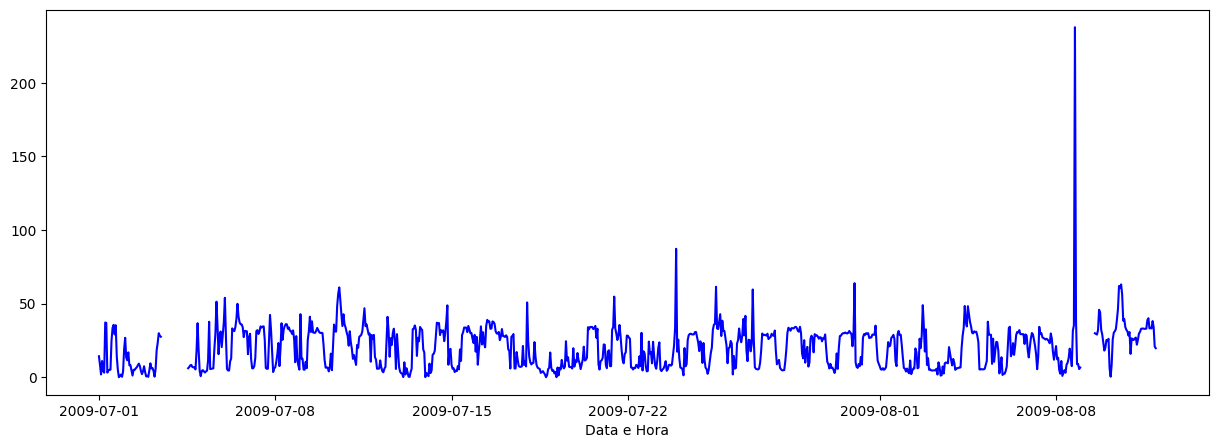

In [4]:
#Transforma a Coluna Data em DateTime
df['DateTime'] = pd.to_datetime(df['Data'])

#Torna a Coluna DateTime o índice do DataFrame
df = df.set_index(df['DateTime'])

#Análise Gráfica dos Dados
plt.figure(figsize=(15,5))
plt.plot(df['DateTime'], df['Preco'], 'b')
plt.xlabel('Data e Hora')
plt.show()

In [5]:
#Clona o DataFrame e Normaliza as Colunas pela primeira amostra
df_clone = df[:]
df_clone['Preco'] = df['Preco'] / df['Preco'].iloc[0]

#Copia apenas as colunas de interesse do Clone para o novo DataFrame
df_norm = df_clone[['Preco']]

#Clona o DataFrame normalizado para um novo
df_lagged = df_norm[:]

#Determina os atrasos (em amostras)
lags = (1, 2)

#Gera o DataFrame com as Colunas de Atraso
df_lagged = df_norm.assign(**{f'{col}_t-{lag}': df_norm[col].shift(lag) for lag in lags for col in df_norm})
df_lagged

,Preco,Preco_t-1,Preco_t-2
DateTime,,,
2009-07-01 00:00:00,1.000000,NaN,NaN
2009-07-01 01:00:00,0.591579,1.000000,NaN
2009-07-01 02:00:00,0.131930,0.591579,1.000000
2009-07-01 03:00:00,0.771930,0.131930,0.591579
2009-07-01 04:00:00,0.295439,0.771930,0.131930
...,...,...,...
2009-08-11 19:00:00,2.324211,2.353684,2.327719
2009-08-11 20:00:00,2.676491,2.324211,2.353684
2009-08-11 21:00:00,2.388772,2.676491,2.324211


In [6]:
#Calcula Média Móvel Simples
tamanho_janela = 10 #em amostras
janelas = df_norm['Preco'].rolling(tamanho_janela)
MA = janelas.mean()
df_ext_feat1 = pd.DataFrame(MA, index=df_norm.index)
df_ext_feat1.rename(columns={'Preco': f'MA{tamanho_janela}_Preco'}, inplace=True)
print(df_ext_feat1)

tamanho_janela = 20 #em amostras
janelas = df_norm['Preco'].rolling(tamanho_janela)
MA = janelas.mean()
df_ext_feat2 = pd.DataFrame(MA, index=df_norm.index)
df_ext_feat2.rename(columns={'Preco': f'MA{tamanho_janela}_Preco'}, inplace=True)
print(df_ext_feat2)

                     MA10_Preco
DateTime                       
2009-07-01 00:00:00         NaN
2009-07-01 01:00:00         NaN
2009-07-01 02:00:00         NaN
2009-07-01 03:00:00         NaN
2009-07-01 04:00:00         NaN
...                         ...
2009-08-11 19:00:00    2.410667
2009-08-11 20:00:00    2.446316
2009-08-11 21:00:00    2.453053
2009-08-11 22:00:00    2.368281
2009-08-11 23:00:00    2.275579

[1008 rows x 1 columns]
                     MA20_Preco
DateTime                       
2009-07-01 00:00:00         NaN
2009-07-01 01:00:00         NaN
2009-07-01 02:00:00         NaN
2009-07-01 03:00:00         NaN
2009-07-01 04:00:00         NaN
...                         ...
2009-08-11 19:00:00    2.157684
2009-08-11 20:00:00    2.198772
2009-08-11 21:00:00    2.228246
2009-08-11 22:00:00    2.212491
2009-08-11 23:00:00    2.189368

[1008 rows x 1 columns]


In [7]:
#Junção de Dois DataFrames
df_lag_ext = pd.merge(df_lagged, df_ext_feat1, left_index = True, right_index = True, how = 'inner')
df_lag_ext = pd.merge(df_lag_ext, df_ext_feat2, left_index = True, right_index = True, how = 'inner')
df_lag_ext = df_lag_ext.dropna()
df_lag_ext

,Preco,Preco_t-1,Preco_t-2,MA10_Preco,MA20_Preco
DateTime,,,,,
2009-07-01 19:00:00,0.000000,0.358596,0.983860,1.318456,1.096035
2009-07-01 20:00:00,0.068772,0.000000,0.358596,1.290456,1.049474
2009-07-01 21:00:00,0.125614,0.068772,0.000000,1.267018,1.026175
2009-07-01 22:00:00,0.021053,0.125614,0.068772,1.093193,1.020632
2009-07-01 23:00:00,0.272281,0.021053,0.125614,0.884702,0.995649
...,...,...,...,...,...
2009-08-11 19:00:00,2.324211,2.353684,2.327719,2.410667,2.157684
2009-08-11 20:00:00,2.676491,2.324211,2.353684,2.446316,2.198772
2009-08-11 21:00:00,2.388772,2.676491,2.324211,2.453053,2.228246


In [8]:
#Calcula a Correlação de Pearson - Busca por uma Relação Linear
corr_p = df_lag_ext.corr(method ='pearson')
corr_p

,Preco,Preco_t-1,Preco_t-2,MA10_Preco,MA20_Preco
Preco,1.000000,0.598881,0.451706,0.496600,0.320855
Preco_t-1,0.598881,1.000000,0.599031,0.598687,0.375987
Preco_t-2,0.451706,0.599031,1.000000,0.668715,0.418840
MA10_Preco,0.496600,0.598687,0.668715,1.000000,0.752884
MA20_Preco,0.320855,0.375987,0.418840,0.752884,1.000000


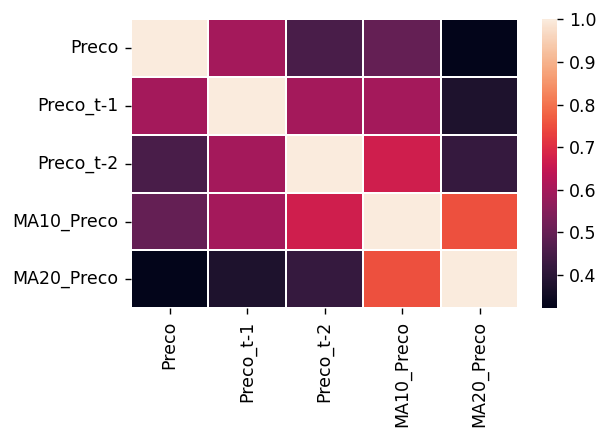

In [9]:
#Plota do Mapa de Calor da Correlação de Pearson
plt.figure(figsize=(5,3), dpi = 125)
sns.heatmap(corr_p, annot=False, fmt=".1f", linewidth=.1)
plt.show()

In [10]:
#Define as colunas que serão variáveis de entrada - explicativas
features1 = df_lag_ext.columns[[1, 2]]
features2 = df_lag_ext.columns[[3, 4]]
features3 = df_lag_ext.columns[[1, 2, 3, 4]]
print(features1)
print(features2)
print(features3)

Index(['Preco_t-1', 'Preco_t-2'], dtype='object')
Index(['MA10_Preco', 'MA20_Preco'], dtype='object')
Index(['Preco_t-1', 'Preco_t-2', 'MA10_Preco', 'MA20_Preco'], dtype='object')


In [11]:
#Define a coluna que será variável de saída - interesse
target = df_lag_ext.columns[[0]]
target

Index(['Preco'], dtype='object')

In [12]:
#Separação de Dados para Ajuste e Validação dos Modelos
df_t_ajuste1 = df_lag_ext['2009-07-01 00:00:00':'2009-07-31 23:00:00'].index.values
df_t_validacao1 = df_lag_ext['2009-08-01 00:00:00':].index.values
df_dados_ajuste1 = df_lag_ext['2009-07-01 00:00:00':'2009-07-31 23:00:00']
df_dados_validacao1 = df_lag_ext['2009-08-01 00:00:00':]

df_t_ajuste2 = df_lag_ext['2009-07-01 00:00:00':'2009-07-31 23:00:00'].index.values
df_t_validacao2 = df_lag_ext['2009-08-01 00:00:00':].index.values
df_dados_ajuste2 = df_lag_ext['2009-07-01 00:00:00':'2009-07-31 23:00:00']
df_dados_validacao2 = df_lag_ext['2009-08-01 00:00:00':]

df_t_ajuste3 = df_lag_ext['2009-07-01 00:00:00':'2009-07-31 23:00:00'].index.values
df_t_validacao3 = df_lag_ext['2009-08-01 00:00:00':].index.values
df_dados_ajuste3 = df_lag_ext['2009-07-01 00:00:00':'2009-07-31 23:00:00']
df_dados_validacao3 = df_lag_ext['2009-08-01 00:00:00':]

X_ajuste1 = df_dados_ajuste1[features1].values
Y_ajuste1 = df_dados_ajuste1[target].values
X_validacao1 = df_dados_validacao1[features1].values
Y_validacao1 = df_dados_validacao1[target].values

X_ajuste2 = df_dados_ajuste2[features2].values
Y_ajuste2 = df_dados_ajuste2[target].values
X_validacao2 = df_dados_validacao2[features2].values
Y_validacao2 = df_dados_validacao2[target].values

X_ajuste3 = df_dados_ajuste3[features3].values
Y_ajuste3 = df_dados_ajuste3[target].values
X_validacao3 = df_dados_validacao3[features3].values
Y_validacao3 = df_dados_validacao3[target].values

In [13]:
# Parametrização de Modelo de Regressão Linear
from sklearn.linear_model import LinearRegression

modelo_RL1 = LinearRegression().fit(X_ajuste1, Y_ajuste1)
modelo_RL2 = LinearRegression().fit(X_ajuste2, Y_ajuste2)
modelo_RL3 = LinearRegression().fit(X_ajuste3, Y_ajuste3)

In [14]:
df_previsto_RL1 = modelo_RL1.predict(X_validacao1)
df_previsto_RL1_denorm = df_previsto_RL1 * df['Preco'].iloc[0]

df_previsto_RL2 = modelo_RL2.predict(X_validacao2)
df_previsto_RL2_denorm = df_previsto_RL2 * df['Preco'].iloc[0]

df_previsto_RL3 = modelo_RL3.predict(X_validacao3)
df_previsto_RL3_denorm = df_previsto_RL3 * df['Preco'].iloc[0]

In [15]:
from sklearn.metrics import (mean_absolute_error, mean_squared_error)

MAE1 = mean_absolute_error(y_true=Y_validacao1, y_pred=df_previsto_RL1_denorm)
MAE2 = mean_absolute_error(y_true=Y_validacao2, y_pred=df_previsto_RL2_denorm)
MAE3 = mean_absolute_error(y_true=Y_validacao3, y_pred=df_previsto_RL3_denorm)
print(f"Modelo 1 - MAE: {round(MAE1, 2)} // Modelo 2 - MAE: {round(MAE2, 2)} // Modelo 3 - MAE: {round(MAE3, 2)}")

MSE1 = mean_squared_error(y_true=Y_validacao1, y_pred=df_previsto_RL1_denorm)
MSE2 = mean_squared_error(y_true=Y_validacao2, y_pred=df_previsto_RL2_denorm)
MSE3 = mean_squared_error(y_true=Y_validacao3, y_pred=df_previsto_RL3_denorm)
print(f"Modelo 1 - RMSE: {round((MSE1**(1/2)), 2)} // Modelo 2 - RMSE: {round((MSE2**(1/2)), 2)} // Modelo 3 - RMSE: {round((MSE3**(1/2)), 2)}")

r_sq1 = modelo_RL1.score(X_validacao1, Y_validacao1)
r_sq2 = modelo_RL2.score(X_validacao2, Y_validacao2)
r_sq3 = modelo_RL3.score(X_validacao3, Y_validacao3)
print(f"Modelo 1 - R2: {round(r_sq1, 2)} // Modelo 2 - R2: {round(r_sq2, 2)} // Modelo 3 - R2: {round(r_sq3, 2)}")

Modelo 1 - MAE: 19.39 // Modelo 2 - MAE: 19.03 // Modelo 3 - MAE: 19.39
Modelo 1 - RMSE: 23.16 // Modelo 2 - RMSE: 20.44 // Modelo 3 - RMSE: 23.09
Modelo 1 - R2: 0.18 // Modelo 2 - R2: 0.21 // Modelo 3 - R2: 0.2


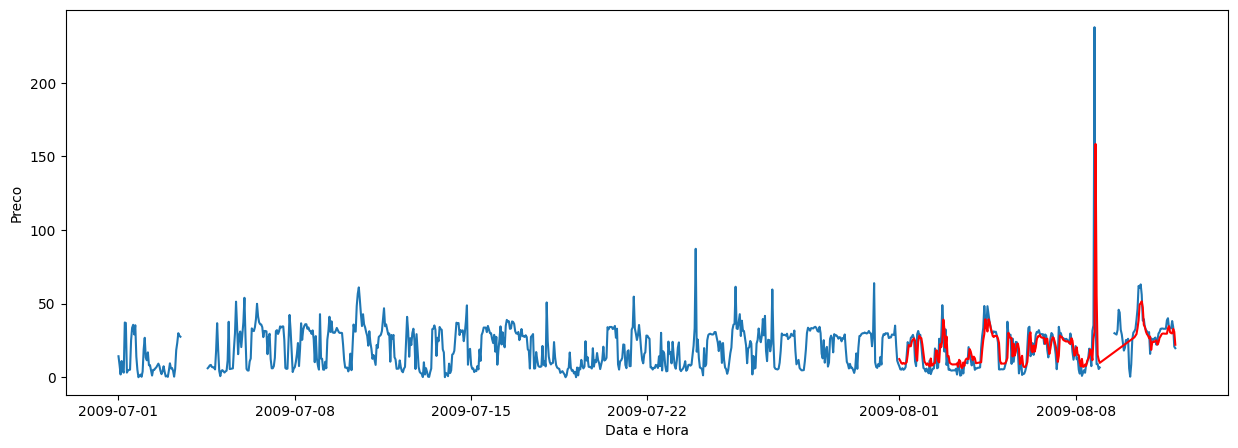

In [19]:
plt.figure(figsize=(15,5))
plt.plot(df['DateTime'], df['Preco'])
plt.plot(df_dados_validacao1.index, df_previsto_RL1_denorm, 'r')
plt.ylabel('Preco')
plt.xlabel('Data e Hora')
plt.show()